# Práctica 04: Regresión Lineal y Logística con Dataset Titanic

**Materia:** Análisis Estadístico Multivariable  
**Profesor:** Luis Alvarado  
**Institución:** ITESO, Universidad Jesuita de Guadalajara  

**Equipo:**
- Gael Rendón Mendoza
- Lambda Remiel Heredia
- José García Fernández Del Valle

---

## Introducción al dataset Titanic
El 15 de abril de 1912, el RMS Titanic —el transatlántico de pasajeros más grande y lujoso del mundo en su época— se hundió en el Océano Atlántico Norte tras chocar contra un iceberg durante su viaje inaugural de Southampton a Nueva York. Esta tragedia marítima resultó en la pérdida de la vida de más de 1,500 personas de las más de 2,200 que iban a bordo, convirtiéndose en uno de los desastres navales más tristemente célebres de la historia moderna.

En el ámbito de la estadística y el aprendizaje automático (Machine Learning), el dataset del Titanic es uno de los conjuntos de datos más famosos, utilizados y estudiados del mundo. Sirve como el "hola mundo" de la ciencia de datos por varias razones: contiene una mezcla rica de variables tanto numéricas como categóricas, presenta valores faltantes reales que exigen técnicas de limpieza e imputación, y permite modelar problemas tanto de regresión como de clasificación binaria. Su popularidad radica en que es intuitivo pero lo suficientemente complejo como para evaluar la robustez de diferentes modelos predictivos y probar supuestos estadísticos.

Para esta práctica, utilizaremos un subconjunto de las variables disponibles en el dataset, las cuales representan las siguientes características de los pasajeros:

Survived: Variable dependiente o de respuesta de naturaleza binaria que indica si el pasajero sobrevivió (1) o no sobrevivió (0).

Pclass: La clase socioeconómica del pasajero (1 = Primera clase, 2 = Segunda clase, 3 = Tercera clase), frecuentemente usada como un proxy del estatus socioeconómico.

Sex: El género biológico del pasajero, un factor histórico clave debido al protocolo de evacuación de "mujeres y niños primero".

Age: La edad del pasajero en años, permitiendo analizar cómo la etapa de vida influyó en las probabilidades de supervivencia o en otras dinámicas del viaje.

Fare: El precio del boleto pagado por el pasajero, reflejo directo de la riqueza o la clase de acomodación a bordo.

Embarked: El puerto donde el pasajero abordó el barco (C = Cherbourg, Q = Queenstown, S = Southampton).

---

## 0. Configuración inicial

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf 
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 110,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
})

%matplotlib inline

### Carga del dataset

Si tienes conexión, `seaborn` descarga el dataset directamente. Si falla, usa la URL alterna que viene en las instrucciones del PDF.

In [3]:
titanic = sns.load_dataset('titanic')

print("Dataset cargado exitosamente")
print(f"Dimensiones: {titanic.shape}")
titanic.head()

Dataset cargado exitosamente
Dimensiones: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
print(titanic.info())
print("\nEstadísticos descriptivos:")
print(titanic.describe())
print("\nValores faltantes por columna:")
print(titanic.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None

Estadísticos descriptivos:
         survived      pclass         age     

---
# PARTE 1: Regresión Lineal

**Objetivo:** construir un modelo de regresión lineal que prediga `Age` en función de `Fare`.

$$\text{Age} = \beta_0 + \beta_1 \cdot \text{Fare} + \varepsilon$$

---

## 1. Análisis Exploratorio

### 1b. Estadísticos descriptivos de `Age` y `Fare`

Calcula media, mediana, desviación estándar, mín, máx, cuartiles, y reporta valores faltantes de ambas variables.

In [5]:
# Estadísticos descriptivos y valores faltantes de age y fare
display(titanic[['age', 'fare']].describe())
print("\nPorcentaje de valores faltantes:")
display((titanic[['age', 'fare']].isna().mean() * 100).round(2))


,age,fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200



Porcentaje de valores faltantes:


age     19.87
fare     0.00
dtype: float64

Interpretacion:

En cuanto a los valores faltantes, la variable Age presenta aproximadamente 19.87% de datos nulos (177 de 891 registros, ya que solo 714 tienen edad registrada). Si bien es una proporción considerable, se mantiene por debajo de un *threshold* común de 30–35% utilizado para decidir si una variable debe descartarse, por lo que optamos por conservarla e imputar los valores faltantes con la mediana, redondeada al entero más cercano, dado que la mediana es más robusta frente a la asimetría y los valores extremos que pueda presentar la distribución de edades. En contraste, Fare no presenta ningún valor faltante (891 registros completos).

Respecto a los estadísticos descriptivos, la media de Age (29.70 años) es muy cercana a su mediana (28.00 años), lo que sugiere una distribución relativamente simétrica, con una desviación estándar de 14.53 años y un rango que va de 0.42 a 80 años. Fare, en cambio, muestra una media (32.20) considerablemente mayor que su mediana (14.45) —más del doble—, lo cual evidencia una fuerte asimetría positiva explicada por un grupo reducido de pasajeros que pagaron tarifas mucho más altas que el resto (el valor máximo registrado es 512.33, muy por encima del percentil 75 de 31.0). Adicionalmente, se observa un valor mínimo de 0 en Fare, lo cual podría corresponder a tripulación, personal de la naviera o pases sin costo, y se señala como un punto a revisar más adelante.

### 1c. Gráficos exploratorios

- Histogramas con densidad de `Age` y `Fare`
- Scatter plot entre `Fare` y `Age`
- Matriz de correlación con otras variables numéricas relevantes

In [6]:
# Histogramas de Age con densidad
sns.histplot(titanic, x='age', kde=True)

<Axes: xlabel='age', ylabel='Count'>

Se observa que la mayor concentración de pasajeros se encuentra entre los 20 y los 30 años, lo cual coincide con la media (29.70) y la mediana (28.00) calculadas previamente. Sin embargo, la distribución no es perfectamente simétrica: se aprecia un pico adicional cerca de los 0 años, probablemente correspondiente a infantes y niños pequeños, lo que le da a la distribución una ligera forma bimodal. Asimismo, se observan valores hacia edades mayores (hasta 80 años) que forman una cola extendida hacia la derecha, consistente con una leve asimetría positiva.

In [7]:
# Histograma de Fare con densidad
sns.histplot(titanic, x='fare', kde=True)

<Axes: xlabel='age', ylabel='Count'>

Se observa que la mayor concentración de pasajeros se encuentra en tarifas muy bajas (entre 0 y 10), donde se registra el pico máximo con cerca de 300 personas. Sin embargo, la distribución no es simétrica, sino que presenta un fuerte sesgo a la derecha, ya que la gran mayoría de los pasajes se sitúan por debajo de los 50. Asimismo, se aprecian valores dispersos y una larga cola que se extiende hacia la derecha, llegando hasta un máximo superior a 500, lo que es consistente con una fuerte asimetría positiva provocada por las tarifas de lujo o camarotes de primera clase.

In [8]:
# Scatter plot Fare vs Age
sns.scatterplot(titanic, x='fare', y='age')

<Axes: xlabel='age', ylabel='Count'>

El diagrama de dispersión muestra que la tarifa pagada se mantiene relativamente baja (menor a 50) para pasajeros de prácticamente todas las edades, sin que se observe un patrón claro de incremento o disminución conforme aumenta la edad. Los valores atípicos de tarifa (mayores a 200, incluyendo dos casos cercanos a 512) están distribuidos entre distintos grupos de edad, lo que sugiere que la tarifa pagada depende más de otros factores — probablemente la clase del pasaje o el tipo de camarote — que de la edad del pasajero. Esto anticipa una relación lineal débil entre ambas variables.

In [9]:
# Matriz de correlación 
corr = titanic[['age', 'fare', 'pclass', 'sibsp', 'parch', 'survived']].corr()

sns.heatmap(corr, annot=True, cmap='RdBu_r')

<Axes: >

La matriz de correlación confirma que age y fare presentan una correlación muy débil (0.096), consistente con lo observado en el diagrama de dispersión. Sin embargo, no todas las relaciones son despreciables: destaca la correlación negativa moderada entre fare y pclass (−0.55), lo cual tiene sentido ya que pclass está codificada de forma inversa a la categoría del pasaje (1 = primera clase), de modo que pasajeros de clases más altas (valores bajos de pclass) tienden a pagar tarifas más altas. También se observan correlaciones moderadas entre pclass y survived (−0.34) y entre fare y survived (0.26), sugiriendo que tanto la clase como la tarifa pagada están relacionadas con la probabilidad de supervivencia — una variable que retomaremos en la Parte 2. El resto de las correlaciones (por ejemplo, parch con pclass, o sibsp con survived) son cercanas a cero y no representan relaciones relevantes.

### 1d. Coeficiente de correlación de Pearson entre `Age` y `Fare`

In [10]:
age_fare = titanic[['age', 'fare']].dropna()
stats.pearsonr(age_fare['age'], age_fare['fare'])

PearsonRResult(statistic=0.0960666917690389, pvalue=0.010216277504447006)

El coeficiente de correlación de Pearson de $0.096$ indica una relación lineal positiva extremadamente débil entre la edad y la tarifa pagada por los pasajeros. Aunque el valor p ($0.0102$) es menor que el nivel de significancia tradicional de $0.05$ —lo que demuestra que esta ligera tendencia no es producto del azar—, en términos prácticos la asociación es casi nula. Esto significa que la edad de un pasajero no es un factor determinante ni lineal para predecir el costo de su tarifa.

## 2. Ajuste del Modelo

Ajusta el modelo por Máxima Verosimilitud (bajo normalidad de errores, el EMV de OLS coincide con mínimos cuadrados).

In [11]:
# Ajuste del modelo de regresión lineal
modelo = smf.ols('age ~ fare', data=titanic).fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                    age   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     6.632
Date:                Sat, 17 Oct 2026   Prob (F-statistic):             0.0102
Time:                        13:14:41   Log-Likelihood:                -2920.0
No. Observations:                 714   AIC:                             5844.
Df Residuals:                     712   BIC:                             5853.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     28.7842      0.648     44.444      0.0

**Ecuación del modelo ajustado:**

$$\widehat{\text{Age}} = \hat{\beta}_0 + \hat{\beta}_1 \cdot \text{Fare}$$

Sutituyendo con los valores que nos da el resultado quedaria:
- $\hat{\beta}_0$ (Intercept) = 28.7842

- $\hat{\beta}_1$ (fare) = 0.0264

Entonces la ecuación queda:

$$\widehat{\text{Age}} = 28.7842 + 0.0264 \cdot \text{Fare}$$

**Interpretación de los coeficientes:**

El intercepto $\hat{\beta}_0 = 28.7842$ representa la edad predicha por el modelo cuando la tarifa pagada es cero. Por su parte, el coeficiente de la pendiente $\hat{\beta}_1 = 0.0264$ indica que, por cada libra adicional pagada, la edad predicha del pasajero aumenta en apenas 0.0264 años (menos de 10 días), un efecto prácticamente insignificante en términos prácticos. Esto es consistente con la débil correlación de Pearson ($r=0.096$) y el bajo $R^2$ (0.009) obtenidos previamente: la tarifa pagada no es un predictor útil de la edad del pasajero.

## 3. Inferencia Estadística

**Pruebas de hipótesis:**
- Para $\beta_0$: $H_0:\beta_0=0$ vs $H_1:\beta_0\neq0$
- Para $\beta_1$: $H_0:\beta_1=0$ vs $H_1:\beta_1\neq0$

Reporta: t-value, error estándar (SE), grados de libertad ($df=n-2$), p-value (bilateral, $\alpha=0.05$) e intervalos de confianza al 95% para cada coeficiente.

$$t = \frac{\hat{\beta}_j}{SE(\hat{\beta}_j)} \qquad \hat{\beta}_j \pm t_{n-2,0.025}\cdot SE(\hat{\beta}_j)$$

In [12]:
print("Coeficientes:\n", modelo.params)
print("\nErrores estándar:\n", modelo.bse)
print("\nEstadísticos t:\n", modelo.tvalues)
print("\nP-values:\n", modelo.pvalues)
print("\nIntervalos de confianza 95%:\n", modelo.conf_int())
print("\nGrados de libertad:", modelo.df_resid)

Coeficientes:
 Intercept    28.784197
fare          0.026371
dtype: float64

Errores estándar:
 Intercept    0.647646
fare         0.010240
dtype: float64

Estadísticos t:
 Intercept    44.444365
fare          2.575290
dtype: float64

P-values:
 Intercept    1.543150e-207
fare          1.021628e-02
dtype: float64

Intervalos de confianza 95%:
                    0          1
Intercept  27.512673  30.055720
fare        0.006267   0.046475

Grados de libertad: 712.0


**Interpretacion:**

Para ambos coeficientes se realizó una prueba de hipótesis bilateral con $\alpha=0.05$ y $n-2=712$ grados de libertad. Para el intercepto ($H_0:\beta_0=0$), se obtuvo un estadístico $t=44.44$ y un p-value de $1.54\times10^{-207}$, por lo que se rechaza $H_0$ con evidencia abrumadora; el intervalo de confianza al 95%, $[27.51, 30.06]$, no contiene el cero, confirmando el resultado. Sin embargo, esta prueba tiene poca relevancia sustantiva, ya que no es realista esperar que la edad sea cero.

Para la pendiente ($H_0:\beta_1=0$), se obtuvo $t=2.575$ y un p-value de $0.0102$, por lo que también se rechaza $H_0$ a un nivel de significancia del 5%, indicando que existe una relación lineal estadísticamente significativa entre fare y age. No obstante, el intervalo de confianza al 95%, $[0.0063, 0.0465]$, es muy angosto y está muy cerca de cero, lo que confirma que, si bien la relación es estadísticamente distinta de cero, su magnitud práctica es mínima — consistente con la débil correlación de Pearson ($r=0.096$) obtenida en el inciso 1d.

## 4. Verificación de Supuestos

### Supuesto 1: Linealidad

- Gráfico de Residuos vs Valores Predichos
- Prueba RESET de Ramsey ($H_0$: la relación es lineal)

In [13]:
# Residuos vs valores predichos
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.title('Residuos vs Valores Predichos')

Text(0.5, 1.0, 'Residuos vs Valores Predichos')

In [14]:
# Prueba RESET de Ramsey
from statsmodels.stats.diagnostic import linear_reset
reset_test = linear_reset(modelo, power=2, use_f=True)
print(reset_test)

<F test: F=4.13064798501397, p=0.04248439002467431, df_denom=711, df_num=1>


Linealidad: Si bien el gráfico de residuos vs. valores predichos no muestra un patrón curvo evidente, la prueba RESET de Ramsey ($F=4.13$, $p=0.0425$) rechaza marginalmente la hipótesis nula de linealidad al 5% de significancia. Este resultado, al estar muy cerca del umbral, probablemente refleja la influencia de los valores atípicos en Fare más que una curvatura real en la relación.

### Supuesto 2: Normalidad de Errores

- Q-Q Plot de los residuos
- Prueba Shapiro-Wilk ($H_0$: los errores son normales)
- Prueba Jarque-Bera (asimetría y curtosis)

In [15]:
# Q-Q plot
sm.qqplot(modelo.resid, line='45')
plt.title('Q-Q Plot de los residuos')

Text(0.5, 1.0, 'Q-Q Plot de los residuos')

In [16]:
# Shapiro-Wilk y Jarque-Bera
shapiro_test = stats.shapiro(modelo.resid)
jb_test = stats.jarque_bera(modelo.resid)
print("Shapiro-Wilk:", shapiro_test)
print("Jarque-Bera:", jb_test)

Shapiro-Wilk: ShapiroResult(statistic=0.9837729788307186, pvalue=4.0920410383167147e-07)
Jarque-Bera: SignificanceResult(statistic=18.011371572588928, pvalue=0.0001227101133449912)


Normalidad: Tanto Shapiro-Wilk ($p=4.09\times10^{-7}$) como Jarque-Bera ($p=0.000123$) rechazan la hipótesis de normalidad, consistente con la fuerte desviación observada en el Q-Q plot. Esto se explica por la marcada asimetría de Fare detectada en el EDA, que se transmite a los residuos. Dado el tamaño de muestra ($n=714$), esta violación es menos crítica gracias al Teorema Central del Límite.

### Supuesto 3: Homocedasticidad (Varianza Constante)

- Gráfico Residuos vs Valores Predichos (dispersión uniforme vs. patrón de embudo)
- Prueba de Breusch-Pagan ($H_0$: varianza constante)

In [17]:
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.title('Residuos vs Valores Predichos')

Text(0.5, 1.0, 'Residuos vs Valores Predichos')

In [18]:
# Prueba de Breusch-Pagan
from statsmodels.stats.diagnostic import het_breuschpagan
bp_test = het_breuschpagan(modelo.resid, modelo.model.exog)
labels = ['LM Statistic', 'LM p-value', 'F-Statistic', 'F p-value']
print(dict(zip(labels, bp_test)))

{'LM Statistic': 1.5001733257078136, 'LM p-value': 0.2206446948564209, 'F-Statistic': 1.4991209371791734, 'F p-value': 0.22121162926074273}


Homocedasticidad: Pese a que el gráfico muestra menor densidad de puntos en la zona de valores predichos altos, no se observa un patrón de embudo claro. La prueba de Breusch-Pagan ($LM=1.50$, $p=0.221$) no rechaza la hipótesis de varianza constante, por lo que se concluye que este supuesto sí se cumple.

### Supuesto 4: Independencia de Errores

- Estadístico de Durbin-Watson (cercano a 2 es deseable, rango 0-4)
- Gráfico ACF de los residuos

In [19]:
# Durbin-Watson y gráfico ACF
from statsmodels.stats.stattools import durbin_watson
dw = durbin_watson(modelo.resid)
print("Durbin-Watson:", dw)

from statsmodels.graphics.tsaplots import plot_acf
plot_acf(modelo.resid, lags=20)
plt.title('ACF de los residuos')

Durbin-Watson: 1.890941396599215


Text(0.5, 1.0, 'ACF de los residuos')

Independencia: El estadístico de Durbin-Watson (1.89) está muy cerca del valor ideal de 2, y el gráfico ACF confirma que ningún rezago sobresale de la banda de significancia. Se concluye que el supuesto de independencia de los errores se cumple.

### Conclusiones generales

|Supuesto	|Prueba	|Resultado	|¿Se cumple?|
|-|-|-|-|
|Linealidad	|RESET	|p=0.0425	|❌ Se rechaza (borderline)|
|Normalidad	|Shapiro-Wilk / Jarque-Bera|	p<0.001 ambas|	❌ No se cumple|
|Homocedasticidad	|Breusch-Pagan|	p=0.221	|✅ Se cumple|
|Independencia	|Durbin-Watson / ACF|	DW=1.89	|✅ Se cumple|

En conjunto, el modelo cumple de forma satisfactoria los supuestos de homocedasticidad e independencia de los errores, pero presenta violaciones en los supuestos de linealidad y, sobre todo, normalidad. No obstante, dado el tamaño de muestra considerable ($n=714$), el Teorema Central del Límite atenúa el impacto de la no-normalidad sobre la validez de las pruebas de hipótesis e intervalos de confianza calculados en el inciso 3, por lo que dichas conclusiones se mantienen razonablemente confiables. Es importante señalar que ambas violaciones —la no-linealidad marginal detectada por la prueba RESET y la fuerte desviación de normalidad— comparten probablemente un mismo origen: la pronunciada asimetría de Fare, caracterizada por un grupo reducido de tarifas extremadamente altas, que ya había sido identificada desde el análisis exploratorio. Más que un problema de especificación del modelo, esto sugiere que la limitación principal no es el incumplimiento de los supuestos, sino la debilidad intrínseca de la relación entre Fare y Age, consistente con el bajo poder explicativo observado ($R^2=0.009$).

## 5. Métricas de Desempeño del Modelo

Calcula e interpreta: $R^2$, $R^2_{adj}$, RMSE y MAE.

$$R^2 = 1-\frac{SS_{res}}{SS_{tot}} \qquad R^2_{adj}=1-\frac{(1-R^2)(n-1)}{n-k-1} \qquad RMSE=\sqrt{\frac{SS_{res}}{n-2}} \qquad MAE=\frac{1}{n}\sum_{i=1}^n|y_i-\hat{y}_i|$$

In [20]:
r2 = modelo.rsquared
r2_adj = modelo.rsquared_adj
print(f"R²: {r2:.4f}")
print(f"R² ajustado: {r2_adj:.4f}")

n = modelo.nobs
k = 1  # un solo predictor

rmse = np.sqrt((modelo.resid**2).sum() / (n - k - 1))
mae = modelo.resid.abs().mean()

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

R²: 0.0092
R² ajustado: 0.0078
RMSE: 14.4695
MAE: 11.2459


El modelo explica apenas el 0.92% de la variabilidad de Age ($R^2=0.0092$), con un $R^2$ ajustado prácticamente idéntico (0.0078) dado que se trata de un único predictor. En términos de error absoluto, el RMSE es de 14.47 años y el MAE de 11.25 años, siendo el RMSE mayor como es de esperarse al penalizar más los errores grandes. El hallazgo más revelador es que el RMSE (14.47) es casi idéntico a la desviación estándar de Age calculada en el análisis exploratorio (14.53), lo cual indica que el modelo apenas logra mejorar, de forma marginal, sobre una predicción ingenua que asignara la edad promedio a todos los pasajeros. Esto confirma, desde la perspectiva del error de predicción, la conclusión ya anticipada por el bajo coeficiente de correlación y de determinación: Fare no es un predictor útil de Age en este dataset.

## 6. Conclusiones de la Regresión Lineal

- ¿Existe relación significativa entre tarifa y edad? 
    
    Existe una relación lineal estadísticamente significativa entre Fare y Age ($\hat{\beta}_1=0.0264$, $p=0.0102$), por lo que se rechaza la hipótesis nula de que no hay relación. Sin embargo, la magnitud de esta relación es prácticamente insignificante: el coeficiente de correlación de Pearson ($r=0.096$) y el coeficiente de determinación ($R^2=0.0092$) indican que Fare explica menos del 1% de la variabilidad en Age. En otras palabras, la significancia estadística no implica relevancia práctica.
- ¿Se cumplen los supuestos del modelo? Implicaciones de las violaciones.
    
    El modelo cumple los supuestos de homocedasticidad e independencia de los errores, pero presenta violaciones en linealidad (de forma marginal) y, particularmente, en normalidad de los residuos. No obstante, dado el tamaño de muestra considerable, estas violaciones tienen un impacto limitado sobre la validez de las inferencias realizadas, gracias al Teorema Central del Límite. Ambas violaciones comparten un origen común: la fuerte asimetría de Fare.
- ¿Qué tan confiable es el modelo para predicciones, según las métricas? 

    La confiabilidad predictiva del modelo es muy baja. El RMSE (14.47 años) es prácticamente idéntico a la desviación estándar de Age (14.53 años), lo que indica que el modelo apenas mejora sobre una predicción ingenua que asignara la edad promedio a todos los pasajeros. Esto, junto con el bajo $R^2$ (0.92%), confirma que Fare por sí solo no es un predictor útil de Age.    
- ¿Qué mejoras sugerirías para futuros análisis? 

    Para futuros análisis se recomienda: (1) construir un modelo de regresión múltiple que incluya otros predictores con mayor correlación con Age, como Pclass (−0.37) o Sibsp (−0.31), identificados en la matriz de correlación del análisis exploratorio; (2) aplicar una transformación logarítmica a Fare para reducir su fuerte asimetría, lo cual podría mejorar el cumplimiento de los supuestos de linealidad y normalidad; y (3) investigar el tratamiento de los valores atípicos de Fare (tarifas superiores a 200), que probablemente influyen tanto en la prueba RESET como en la desviación de normalidad observada

---
# PARTE 2: Regresión Logística

**Objetivo:** predecir la probabilidad de supervivencia (`Survived`) en función de `Age`, `Pclass`, `Sex` y `Fare`.

$$P(\text{Survived}=1\mid X) = \frac{1}{1+e^{-(\beta_0+\beta_1\cdot\text{Age}+\cdots)}}$$

---

## 1. Preparación de Datos

### Imputación de valores faltantes
- `Age`: mediana por clase de pasaje (`Pclass`)
- `Fare`: mediana general
- `Embarked`: elimina registros o usa la categoría más frecuente

In [22]:
# Imputación de Age por mediana según Pclass, Fare por mediana general, Embarked
df = titanic[['survived', 'age', 'pclass', 'sex', 'fare', 'embarked']].copy()

print("Valores faltantes ANTES de imputar:")
print(df.isnull().sum())

# Age: mediana por clase de pasaje (Pclass)
print("\nMediana de Age por Pclass:")
print(df.groupby('pclass')['age'].median())
df['age'] = df['age'].fillna(df.groupby('pclass')['age'].transform('median'))

# Fare: mediana general
df['fare'] = df['fare'].fillna(df['fare'].median())

# Embarked: categoría más frecuente (moda)
moda_embarked = df['embarked'].mode()[0]
print(f"\nCategoría más frecuente de Embarked: {moda_embarked}")
df['embarked'] = df['embarked'].fillna(moda_embarked)

Valores faltantes ANTES de imputar:
survived      0
age         177
pclass        0
sex           0
fare          0
embarked      2
dtype: int64

Mediana de Age por Pclass:
pclass
1    37.0
2    29.0
3    24.0
Name: age, dtype: float64

Categoría más frecuente de Embarked: S


### Codificación de variables categóricas
- `Sex`: variable binaria (Female=1, Male=0)
- Reporta antes/después

In [23]:
# Codificación de Sex como binaria
df['sex'] = df['sex'].map({'female': 1, 'male': 0})

### Estandarización (opcional pero recomendado)
Estandariza `Age` y `Fare`. Reporta media y desviación estándar antes y después.

In [24]:
# Estandarización de Age y Fare
# Z-score: (x - media) / desviación estándar
for col in ['age', 'fare']:
    df[col] = (df[col] - df[col].mean()) / df[col].std()

df.head()

,survived,age,pclass,sex,fare,embarked
0,0,-0.533534,3,0,-0.502163,S
1,1,0.674512,1,1,0.786404,C
2,1,-0.231523,3,1,-0.488580,S
3,1,0.448003,1,1,0.420494,S
4,0,0.448003,3,0,-0.486064,S


## 2. Ajuste del Modelo

Ajusta el modelo de regresión logística por Máxima Verosimilitud.

In [ ]:
# print(modelo_log.summary())
modelo_log = smf.logit('survived ~ age + pclass + sex + fare', data=df).fit()
print(modelo_log.summary())

Optimization terminated successfully.
         Current function value: 0.450399
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:               survived   No. Observations:                  891
Model:                          Logit   Df Residuals:                      886
Method:                           MLE   Df Model:                            4
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  0.3236
Time:                        13:27:13   Log-Likelihood:                -401.31
converged:                       True   LL-Null:                       -593.33
Covariance Type:            nonrobust   LLR p-value:                 7.790e-82
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2710      0.315      4.031      0.000       0.653       1.889
age           -0.4833      0.

**Ecuación logit ajustada:**

$$\text{logit}(\hat{p}) = \hat{\beta}_0 + \hat{\beta}_1\cdot\text{Age} + \cdots$$

**Odds Ratios:** $OR=e^{\hat{\beta}_j}$

In [30]:
# Odds ratios
# tip: np.exp(modelo_log.params)
odds_ratios = np.exp(modelo_log.params)
print("Odds Ratios:")
print(odds_ratios.round(4))

Odds Ratios:
Intercept     3.5645
age           0.6167
pclass        0.2924
sex          13.5150
fare          1.0175
dtype: float64


Interpretación de los odds ratios

sex (OR = 13.52): los odds de supervivencia de una mujer son aproximadamente 13.5 veces los de un hombre con la misma edad, clase y tarifa. Es el predictor más fuerte, coherente con el protocolo de “mujeres y niños primero”.

pclass (OR = 0.2924): por cada paso hacia una clase inferior (de 1ª a 2ª, o de 2ª a 3ª), los odds de supervivencia se multiplican por 0.29, es decir, disminuyen aproximadamente 70.8%.

age (OR = 0.6167): por cada aumento de 1 desviación estándar en la edad, los odds de supervivencia se reducen aproximadamente 38.3%. A mayor edad, menor probabilidad de sobrevivir.

fare (OR = 1.0175): por cada aumento de 1 desviación estándar en la tarifa, los odds aumentan apenas 1.75%. Este efecto es prácticamente nulo y no es estadísticamente significativo (p = 0.864).

Intercepto (OR = 3.56): son los odds de supervivencia de un hombre ($\text{Sex}=0$) con edad y tarifa promedio y $\text{Pclass}=0$. Como esa clase no existe, el intercepto no tiene interpretación práctica; actúa solo como constante de ajuste.

## 3. Inferencia Estadística

**Pruebas de Wald** para cada coeficiente: $H_0:\beta_j=0$ vs $H_1:\beta_j\neq0$

$$z = \frac{\hat{\beta}_j}{SE(\hat{\beta}_j)}, \qquad p = 2\cdot P(Z>|z|)$$

Intervalos de confianza al 95%: $\hat{\beta}_j \pm 1.96\cdot SE(\hat{\beta}_j)$

In [ ]:
tabla_or = pd.DataFrame({
    'Coeficiente': modelo_log.params,
    'Odds Ratio': np.exp(modelo_log.params),
    'IC 95% inf (OR)': np.exp(modelo_log.conf_int()[0]),
    'IC 95% sup (OR)': np.exp(modelo_log.conf_int()[1]),
    'p-value': modelo_log.pvalues
}).round(4)
tabla_or

,Coeficiente,Odds Ratio,IC 95% inf (OR),IC 95% sup (OR),p-value
Intercept,1.2710,3.5645,1.9212,6.6133,0.0001
age,-0.4833,0.6167,0.5050,0.7531,0.0000
pclass,-1.2297,0.2924,0.2213,0.3863,0.0000
sex,2.6038,13.5150,9.3547,19.5257,0.0000
fare,0.0173,1.0175,0.8340,1.2412,0.8645


**Interpretación:** ¿qué coeficientes son significativos a $\alpha=0.05$? ¿los IC incluyen el cero?

Interpretación:

A un nivel de significancia de $\alpha = 0.05$, tres de los cuatro predictores resultan estadísticamente significativos: sex, pclass y age. Para los tres, el p-value es menor a 0.001, por lo que se rechaza $H_0:\beta_j=0$.
Sus intervalos de confianza al 95% no incluyen el cero en la escala de los coeficientes, ni el 1 en la escala de los odds ratios, lo cual es consistente con el resultado de la prueba de Wald.


En contraste, fare no es significativa ($p = 0.8645$). Su intervalo de confianza para el OR, [0.83, 1.24], incluye el 1 (equivalente a que el intervalo del coeficiente, [−0.181, 0.216], incluya el cero), por lo que no se rechaza $H_0$. No hay evidencia de que la tarifa aporte información sobre la supervivencia una vez que se controla por clase, edad y sexo.

## 4. Verificación de Supuestos (Adaptados para Logística)

### No colinealidad (VIF)
VIF > 5–10 indica problema.

In [36]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Matriz de diseño del modelo (incluye la constante)
X = modelo_log.model.exog
nombres = modelo_log.model.exog_names

vif = pd.DataFrame({
    'Variable': nombres,
    'VIF': [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})

# El VIF del intercepto no se interpreta
vif = vif[vif['Variable'] != 'Intercept'].round(3)
display(vif)

,Variable,VIF
1,age,1.243
2,pclass,1.737
3,sex,1.054
4,fare,1.478


### Linealidad en el logit
Para variables continuas (`Age`, `Fare`): grafica probabilidades predichas vs. la variable.

<Figure size 1100x660 with 0 Axes>

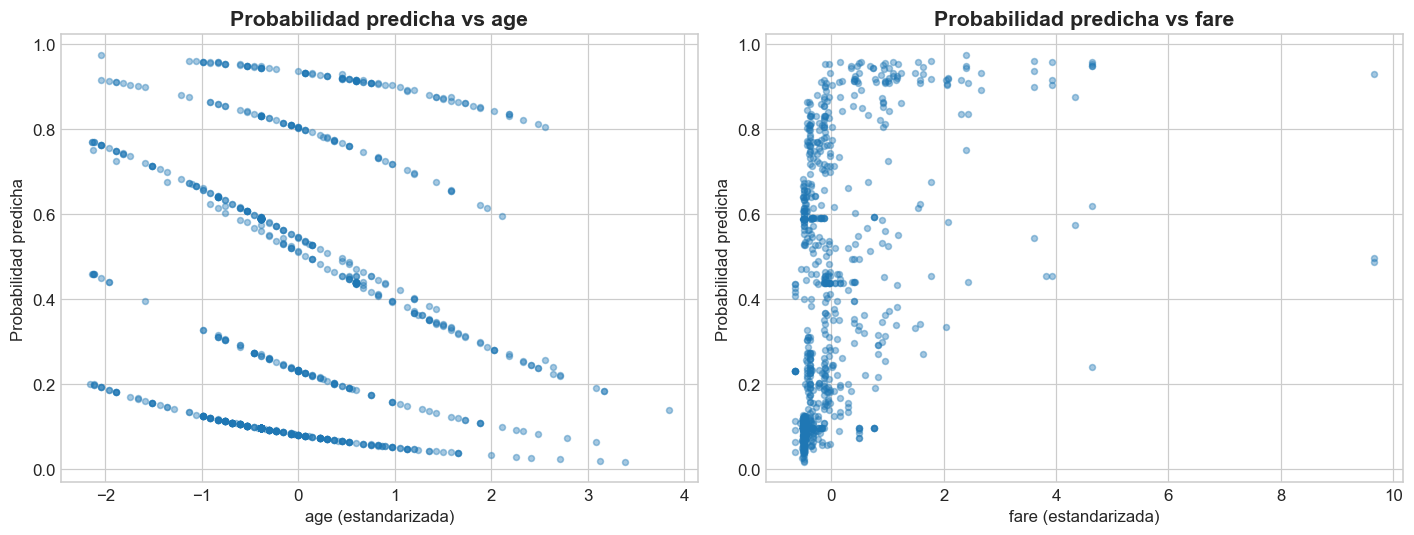

In [37]:
# Gráfico de probabilidades predichas vs Age / Fare
df['prob_pred'] = modelo_log.predict(df)

plt.figure()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, var in zip(axes, ['age', 'fare']):
    ax.scatter(df[var], df['prob_pred'], alpha=0.4, s=15)
    ax.set_xlabel(f'{var} (estandarizada)')
    ax.set_ylabel('Probabilidad predicha')
    ax.set_title(f'Probabilidad predicha vs {var}')
plt.tight_layout()
plt.show()

<Figure size 1430x550 with 0 Axes>

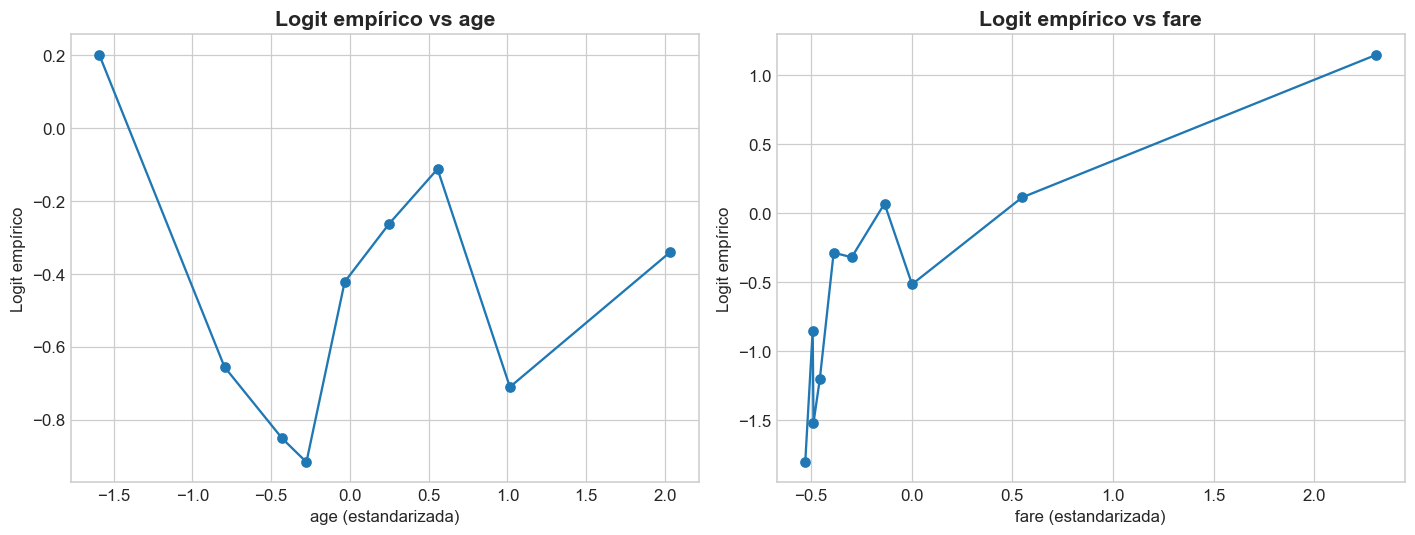

In [38]:
plt.figure(figsize=(13, 5))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, var in zip(axes, ['age', 'fare']):
    bins = pd.qcut(df[var], q=10, duplicates='drop')
    g = df.groupby(bins, observed=True).agg(x=(var, 'mean'), p=('survived', 'mean'))
    g['p'] = g['p'].clip(0.01, 0.99)
    g['logit'] = np.log(g['p'] / (1 - g['p']))
    ax.plot(g['x'], g['logit'], 'o-')
    ax.set_xlabel(f'{var} (estandarizada)')
    ax.set_ylabel('Logit empírico')
    ax.set_title(f'Logit empírico vs {var}')
plt.tight_layout()
plt.show()

In [33]:
eventos = df['survived'].value_counts()
print(eventos)

n_min = eventos.min()          # clase menos frecuente
k = 4                          # número de predictores
print(f"\nEPV = {n_min} / {k} = {n_min / k:.1f}")

survived
0    549
1    342
Name: count, dtype: int64

EPV = 342 / 4 = 85.5


### Tamaño de muestra y casos raros
*(¿Se cumple? Revisa el balance de la variable `Survived`.)*

La variable Survived presenta 549 no sobrevivientes (61.6%) y 342 sobrevivientes (38.4%). La distribución no es perfectamente balanceada, pero el desbalance es moderado: la clase minoritaria representa casi 4 de cada 10 observaciones, lejos de los casos problemáticos de eventos raros, donde la estimación por máxima verosimilitud puede sesgarse. Por lo tanto, no se requieren técnicas de rebalanceo.

## 5. Métricas de Desempeño del Modelo

### Matriz de confusión y métricas de clasificación (punto de corte $p=0.5$)
- Accuracy $=\frac{TP+TN}{Total}$
- Sensibilidad (Recall) $=\frac{TP}{TP+FN}$
- Especificidad $=\frac{TN}{TN+FP}$
- Precisión $=\frac{TP}{TP+FP}$

,Pred: No sobrevivió (0),Pred: Sobrevivió (1)
Real: No sobrevivió (0),467,82
Real: Sobrevivió (1),100,242


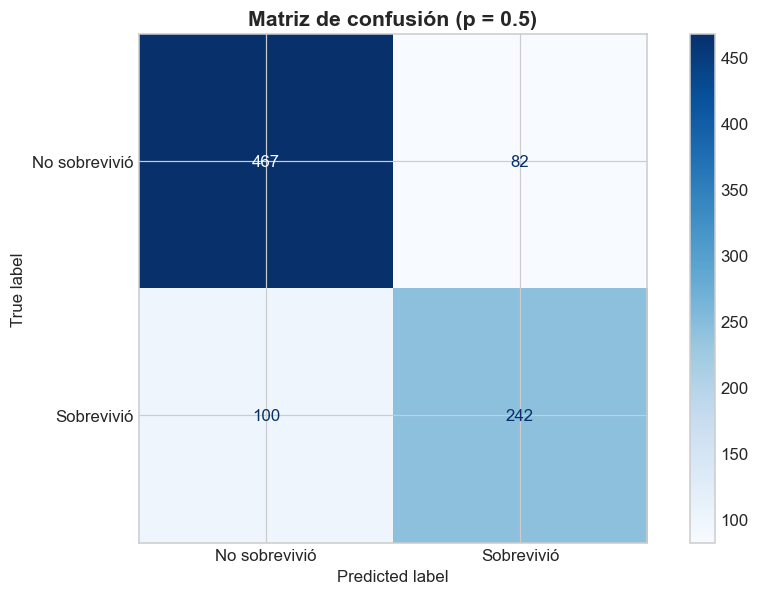

TP = 242, TN = 467, FP = 82, FN = 100
Exactitud (Accuracy):          0.7957
Sensibilidad (Recall / TPR):   0.7076
Especificidad (TNR):           0.8506
Precisión (PPV):               0.7469


In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Probabilidades predichas y clasificación con punto de corte p = 0.5
df['prob_pred'] = modelo_log.predict(df)
df['clase_pred'] = (df['prob_pred'] >= 0.5).astype(int)

# Matriz de confusión (filas = real, columnas = predicho)
cm = confusion_matrix(df['survived'], df['clase_pred'])
TN, FP, FN, TP = cm.ravel()

display(pd.DataFrame(cm,
                     index=['Real: No sobrevivió (0)', 'Real: Sobrevivió (1)'],
                     columns=['Pred: No sobrevivió (0)', 'Pred: Sobrevivió (1)']))

ConfusionMatrixDisplay(cm, display_labels=['No sobrevivió', 'Sobrevivió']).plot(cmap='Blues')
plt.title('Matriz de confusión (p = 0.5)')
plt.show()

# Métricas
exactitud     = (TP + TN) / (TP + TN + FP + FN)
sensibilidad  = TP / (TP + FN)
especificidad = TN / (TN + FP)
precision     = TP / (TP + FP)

print(f"TP = {TP}, TN = {TN}, FP = {FP}, FN = {FN}")
print(f"Exactitud (Accuracy):          {exactitud:.4f}")
print(f"Sensibilidad (Recall / TPR):   {sensibilidad:.4f}")
print(f"Especificidad (TNR):           {especificidad:.4f}")
print(f"Precisión (PPV):               {precision:.4f}")

### Curva ROC y AUC

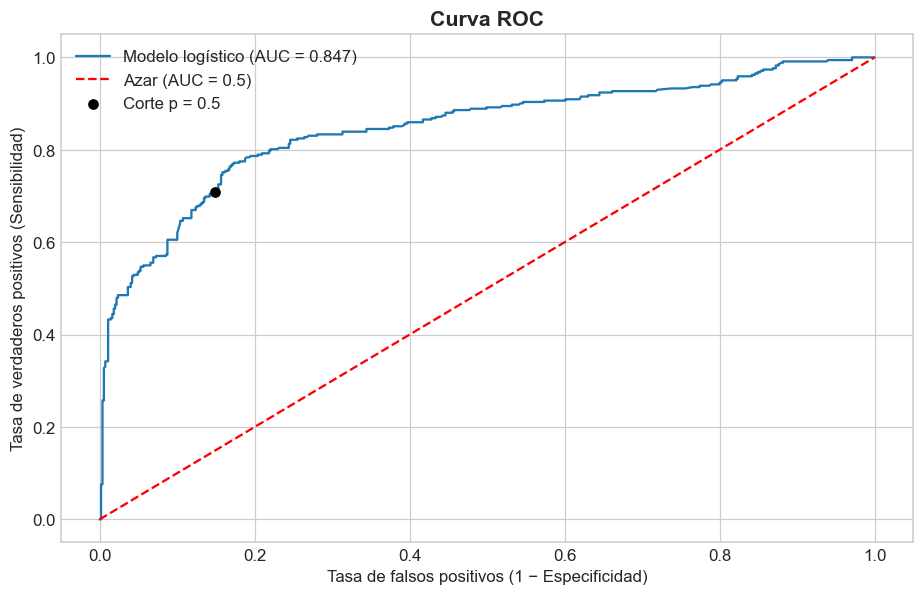

AUC = 0.8471


In [35]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, umbrales = roc_curve(df['survived'], df['prob_pred'])
auc = roc_auc_score(df['survived'], df['prob_pred'])

plt.plot(fpr, tpr, label=f'Modelo logístico (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'r--', label='Azar (AUC = 0.5)')

# Marcar el punto correspondiente al corte p = 0.5
plt.scatter(1 - especificidad, sensibilidad, color='black', zorder=5,
            label='Corte p = 0.5')

plt.xlabel('Tasa de falsos positivos (1 − Especificidad)')
plt.ylabel('Tasa de verdaderos positivos (Sensibilidad)')
plt.title('Curva ROC')
plt.legend()
plt.show()

print(f"AUC = {auc:.4f}")

Interpretación de las métricas
Exactitud (79.57%): el modelo clasifica correctamente a 709 de los 891 pasajeros. Para ponerlo en contexto, un clasificador ingenuo que predijera “no sobrevivió” para todos acertaría 61.6% de las veces (549/891), así que el modelo mejora esa línea base en casi 18 puntos porcentuales.

Sensibilidad (70.76%): de los 342 pasajeros que realmente sobrevivieron, el modelo identifica correctamente a 242. Es decir, aproximadamente 7 de cada 10 sobrevivientes son detectados.

Especificidad (85.06%): de los 549 pasajeros que no sobrevivieron, el modelo identifica correctamente a 467, es decir, más de 85%.

Precisión (74.69%): de los 324 pasajeros que el modelo predijo como sobrevivientes (242 + 82), aproximadamente 75% realmente sobrevivió.

Con un AUC = 0.8471 podemos decir que tenemos un modelo decente.

## 6. Conclusiones de la Regresión Logística

- ¿Cuáles son los predictores más significativos de supervivencia? *(completar)*
Sexo (z = 13.87), clase (z = −8.65) y edad (z = −4.74) son significativos con p < 0.001.

- Interpretación de los Odds Ratios. *(completar)*
Sexo (13.52): una mujer tiene unas 13.5 veces los odds de sobrevivir de un hombre con la misma edad y clase.
Clase (0.29): cada paso a una clase inferior reduce los odds de sobrevivir en ~71%. Es menor a 1 porque un número más alto significa una clase más baja.
Edad (0.62): cada desviación estándar adicional de edad reduce los odds en ~38%.
Tarifa (1.02): sin efecto; su IC [0.83, 1.24] incluye el 1.

- ¿Se cumplen los supuestos adaptados? *(completar)*
Colinealidad: se cumple. Todos los VIF son menores a 5 (age 1.24, pclass 1.74, sex 1.05, fare 1.48). La clase y la tarifa están correlacionadas, pero no lo suficiente para afectar el modelo. Además, la falta de significancia de fare no se debe a colinealidad.
Linealidad en el logit: se cumple para la edad. La edad muestra una tendencia general descendente (a mayor edad, menor supervivencia). La tarifa muestra una relación curva: sube rápido en tarifas bajas y se aplana después, lo que refleja su fuerte asimetría (no lineal).
Tamaño de muestra: se cumple con holgura. EPV = 342 / 4 = 85.5, muy por encima del mínimo de 10.

- Desempeño predictivo (Accuracy, AUC, sensibilidad, especificidad). *(completar)*
Con corte en p = 0.5, la exactitud es 79.6%, la sensibilidad 70.8%, la especificidad 85.1% y la precisión 74.7%. El AUC es 0.847, por lo que el modelo discrimina bien.

- ¿Hay sesgo de clase / desbalance? ¿afecta las predicciones? *(completar)*
Hay 61.6% de no sobrevivientes contra 38.4% de sobrevivientes: un desbalance moderado que no compromete la estimación ni exige rebalancear. Sí se refleja en las predicciones: la especificidad es mayor que la sensibilidad porque, con p = 0.5, el modelo tiende a favorecer la clase mayoritaria (100 falsos negativos contra 82 falsos positivos).

- Recomendaciones de mejora. *(completar)*
Probar una interacción entre sexo y clase, y tratar pclass como categórica.
Ajustar el punto de corte según el objetivo, usando la curva ROC.
Validar con partición entrenamiento/prueba o validación cruzada, porque las métricas se calcularon con los mismos datos del ajuste y pueden ser optimistas.


---
# PARTE 3: Análisis Comparativo

---

### 1. Objetivos diferentes
*(Regresión lineal predice un valor continuo, logística predice probabilidad/clase. ¿Cuál es más apropiado para cada pregunta de investigación?)*

### 2. Supuestos y validación
*(¿Qué supuestos se violaron en la regresión lineal y qué implica? ¿se cumplieron mejor los supuestos adaptados en logística?)*

### 3. Interpretabilidad
*(Compara interpretar un coeficiente en RL (cambio unitario) vs. un Odds Ratio en logística. ¿Cuál es más fácil de explicar a alguien no-estadístico?)*

### 4. Desempeño predictivo
*(RL: RMSE, MAE, R². Logística: Accuracy, AUC, Sensibilidad, Especificidad. ¿Cuál modelo sería más útil en la práctica, en el contexto del Titanic?)*

---
## Conclusiones Generales

*(Síntesis final del equipo.)*